In [38]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/cleaned_ecommerce_sales.csv')

# Dataset overview
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (1005, 11)

Columns:
['order_id', 'order_date', 'customer_id', 'product_name', 'category', 'quantity', 'price', 'discount', 'region', 'payment_method', 'status']

First 5 rows:


,order_id,order_date,customer_id,product_name,category,quantity,price,discount,region,payment_method,status
0,ORD10001,2025-02-01,CUST1175,Vacuum Cleaner,Home & Kitchen,3,13778.0,0.20,South,UPI,Returned
1,ORD10002,2025-11-03,CUST1113,Vacuum Cleaner,Home & Kitchen,3,20722.0,0.00,East,Credit Card,Cancelled
2,ORD10003,2025-06-14,CUST1057,Jacket,Clothing,3,6079.0,0.10,North,Debit Card,Delivered
3,ORD10004,2025-09-13,CUST1089,Microwave,Home & Kitchen,1,13580.0,0.15,North,Cash on Delivery,Cancelled
4,ORD10005,2025-07-01,CUST1011,Vacuum Cleaner,Home & Kitchen,2,8892.0,0.10,East,UPI,Delivered


In [39]:
# missing values
print(df.isnull().sum())

print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


order_id          0
order_date        0
customer_id       8
product_name      0
category          0
quantity          0
price             0
discount          6
region            5
payment_method    4
status            0
dtype: int64
5

Data types:
order_id              str
order_date            str
customer_id           str
product_name          str
category              str
quantity            int64
price             float64
discount          float64
region                str
payment_method        str
status                str
dtype: object



Numerical summary:
          quantity         price    discount
count  1005.000000   1005.000000  999.000000
mean      2.933333  12140.163184    0.096647
std       1.385947  17372.395605    0.069864
min       1.000000    175.000000    0.000000
25%       2.000000   1918.000000    0.050000
50%       3.000000   5736.000000    0.100000
75%       4.000000  13778.000000    0.150000
max       5.000000  88530.000000    0.200000


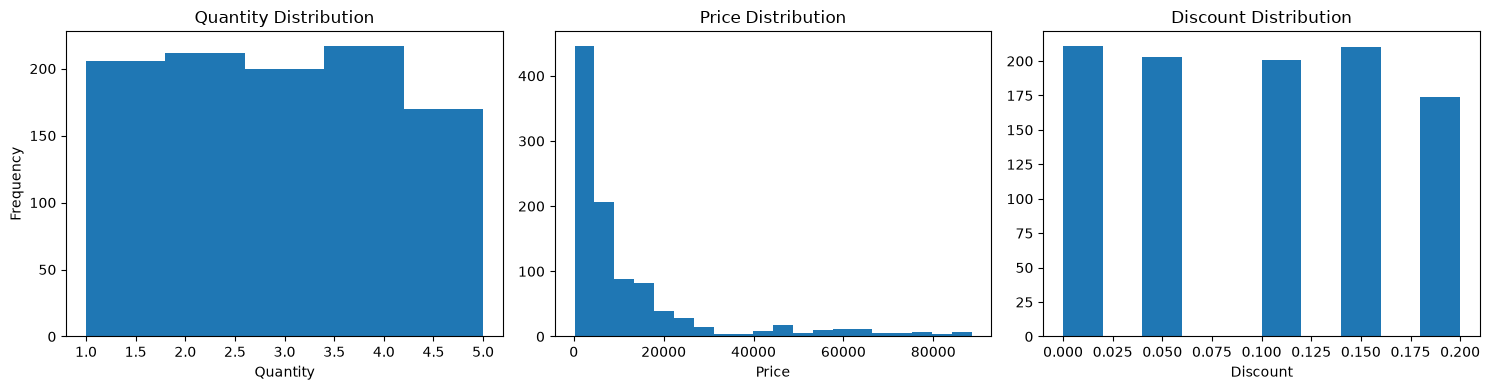

In [40]:
# Step 3 – Numerical analysis

print("\nNumerical summary:")

print(df[['quantity' , 'price' , 'discount']].describe()) 

# Numerical distribution
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(df['quantity'], bins=5)
plt.title('Quantity Distribution')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.subplot(1, 3, 2)
plt.hist(df['price'], bins=20)
plt.title('Price Distribution')
plt.xlabel('Price')

plt.subplot(1, 3, 3)
plt.hist(df['discount'].dropna(), bins=10)
plt.title('Discount Distribution')
plt.xlabel('Discount')

plt.tight_layout()
plt.show()

Category Counts:
category
Electronics       261
Clothing          221
Home & Kitchen    192
Furniture         174
Books             157
Name: count, dtype: int64

Product Counts:
product_name
Smartphone          66
Monitor             51
Headphones          50
Jacket              49
Keyboard            48
Vacuum Cleaner      46
Laptop              46
Jeans               46
Sneakers            43
T-Shirt             43
Desk                43
Cookware Set        43
Microwave           40
Dress               40
Biography           38
Bookshelf           37
Air Fryer           35
Office Chair        34
Programming Book    31
Comics              31
Coffee Table        30
Sofa                30
Cookbook            29
Blender             28
Fiction Novel       28
Name: count, dtype: int64

Order Status Counts:
status
Delivered    777
Pending      116
Cancelled     79
Returned      33
Name: count, dtype: int64

Region Counts:
region
East       213
West       203
South      198
Central    194
N

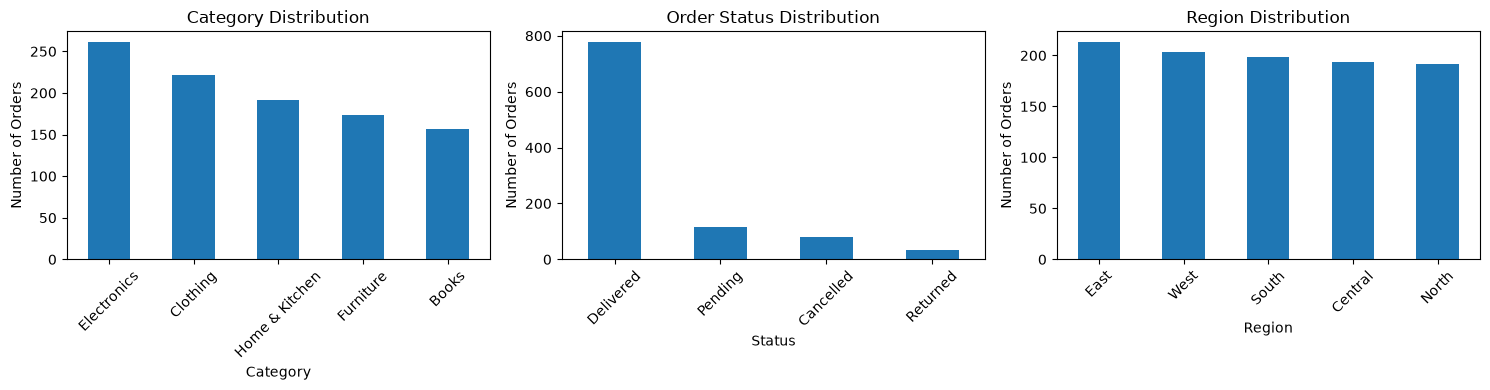

In [41]:
# Categorical data analysis 
# Categorical column analysis

print("Category Counts:")
print(df['category'].value_counts())

print("\nProduct Counts:")
print(df['product_name'].value_counts())

print("\nOrder Status Counts:")
print(df['status'].value_counts())

print("\nRegion Counts:")
print(df['region'].value_counts())

# Visualize categorical data

# Category distribution
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
df['category'].value_counts().plot(kind='bar')
plt.title('Category Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

# Order status distribution
plt.subplot(1, 3, 2)
df['status'].value_counts().plot(kind='bar')
plt.title('Order Status Distribution')
plt.xlabel('Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

# Region distribution
plt.subplot(1, 3, 3)
df['region'].value_counts().plot(kind='bar')
plt.title('Region Distribution')
plt.xlabel('Region')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [42]:
# Step 7: Revenue analysis 

df['total_revenue'] = df['quantity'] * df['price'] * (1 - df['discount'].fillna(0))

print(df[['quantity', 'price', 'discount', 'total_revenue']].head())

   quantity    price  discount  total_revenue
0         3  13778.0      0.20        33067.2
1         3  20722.0      0.00        62166.0
2         3   6079.0      0.10        16413.3
3         1  13580.0      0.15        11543.0
4         2   8892.0      0.10        16005.6


category
Electronics       19631300.30
Furniture          6663957.90
Home & Kitchen     5025607.10
Clothing           1814549.45
Books               258839.85
Name: total_revenue, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

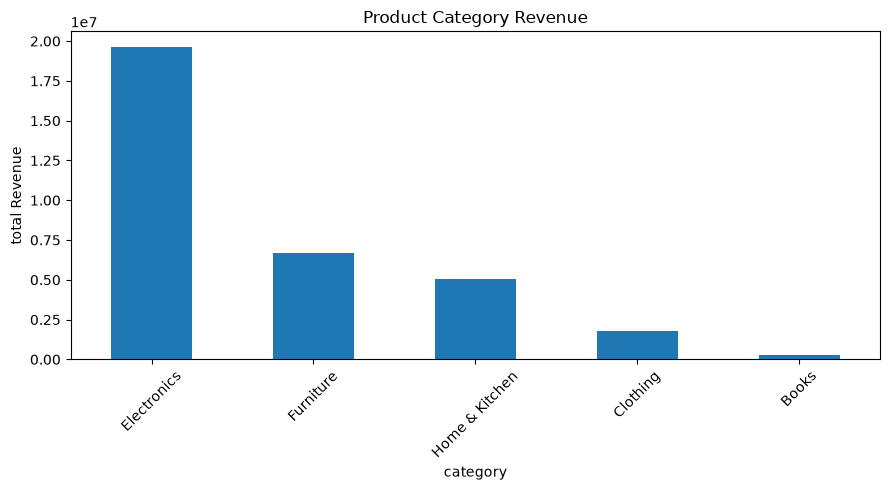

In [43]:
# Step 8 : Revenue by category

category_revenue = (
  df.groupby('category')['total_revenue']
  .sum()
  .sort_values(ascending= False)

)

print(category_revenue)

# Key business insights:
# 1. Electronics generates the highest revenue.
# 2. Furniture ranks second, even though it has fewer orders than Clothing.
# 3. Books generates the lowest revenue.
# 4. Electronics is the leader in both order count and revenue. 

# Step 9 : Visualize category revenue 

plt.figure(figsize=(9 , 5))

category_revenue.plot(kind='bar')

plt.title('Product Category Revenue') 
plt.xlabel('category')
plt.ylabel('total Revenue')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show

month
1     2435661.15
2     2605390.75
3     2160971.20
4     3341214.30
5     2686356.05
6     2856771.20
7     2483845.10
8     3434894.50
9     2927203.45
10    3257130.00
11    2500312.85
12    2704504.05
Name: total_revenue, dtype: float64


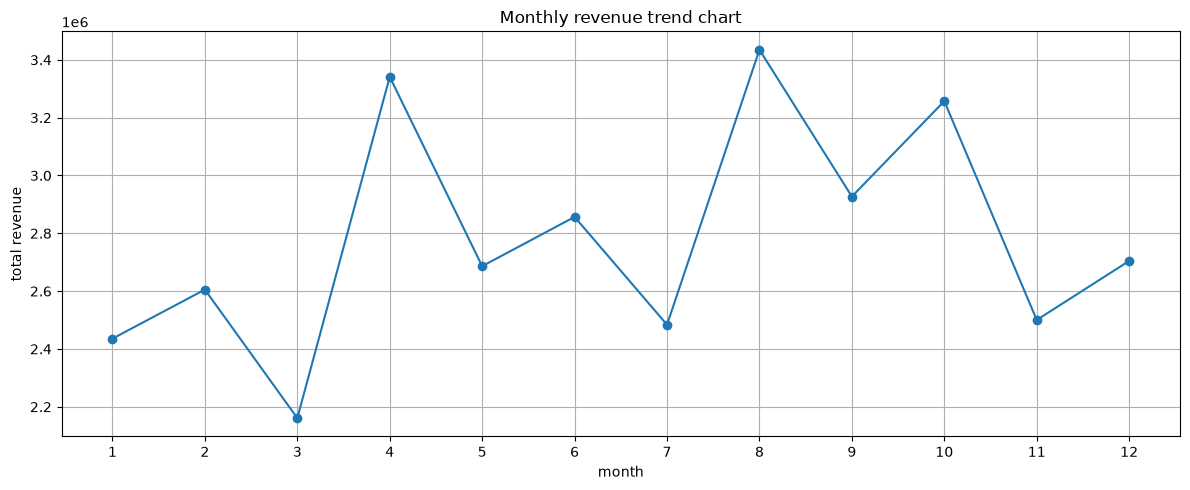

In [44]:
# Step 10 : Monthly revenue analysis 

df['order_date'] = pd.to_datetime(df['order_date'])

df['month'] = df['order_date'].dt.month

monthly_revenue = (

df.groupby('month')['total_revenue']
.sum()


) 

print(monthly_revenue) 

# Monthly revenue trend chart

plt.figure(figsize=(12, 5))

monthly_revenue.plot(kind='line' , marker= 'o')

plt.title('Monthly revenue trend chart')
plt.xlabel('month')
plt.ylabel('total revenue')
plt.xticks(range(1 , 13))
plt.grid(True)
plt.tight_layout()
plt.show()

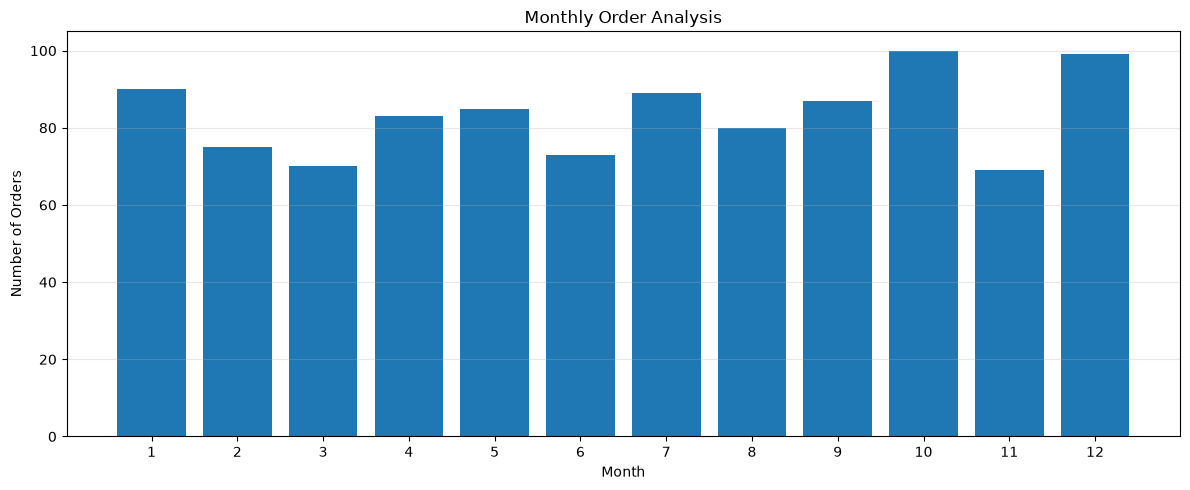

In [45]:
# Monthly Order Analysis 

monthly_orders = df.groupby('month')['order_id'].nunique()

monthly_orders = monthly_orders.astype(int)

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_orders.index,
    monthly_orders.values
)

plt.title('Monthly Order Analysis')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

month
1     2435661.15
2     2605390.75
3     2160971.20
4     3341214.30
5     2686356.05
6     2856771.20
7     2483845.10
8     3434894.50
9     2927203.45
10    3257130.00
11    2500312.85
12    2704504.05
Name: total_revenue, dtype: float64
       total_revenue  previous_month_revenue  growth_percentage
month                                                          
1         2435661.15                     NaN                NaN
2         2605390.75              2435661.15           6.968523
3         2160971.20              2605390.75         -17.057693
4         3341214.30              2160971.20          54.616327
5         2686356.05              3341214.30         -19.599409
6         2856771.20              2686356.05           6.343729
7         2483845.10              2856771.20         -13.054112
8         3434894.50              2483845.10          38.289401
9         2927203.45              3434894.50         -14.780397
10        3257130.00              2927203.45      

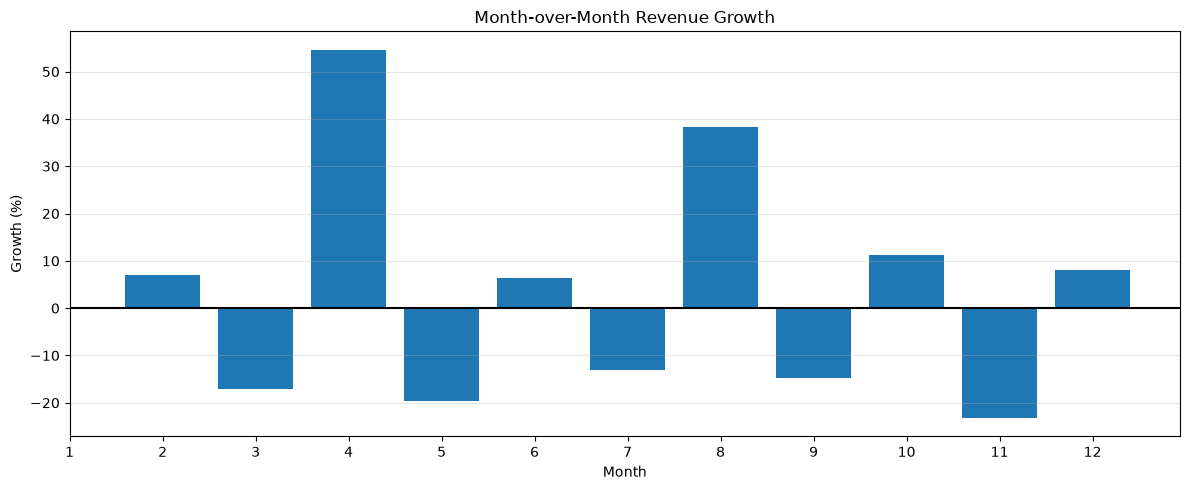

In [46]:
# Month-over-Month (MoM) Revenue Growth Analysis

monthly_revenue = df.groupby('month')['total_revenue'].sum()

print(monthly_revenue) 

monthly_analysis = pd.DataFrame(monthly_revenue)

monthly_analysis['previous_month_revenue'] = (
    monthly_analysis['total_revenue'].shift(1)
)

monthly_analysis['growth_percentage'] = (
    (monthly_analysis['total_revenue'] -
     monthly_analysis['previous_month_revenue'])
    / monthly_analysis['previous_month_revenue']
) * 100

print(monthly_analysis) 

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_analysis.index,
    monthly_analysis['growth_percentage']
)

plt.axhline(0, color='black')
plt.title('Month-over-Month Revenue Growth')
plt.xlabel('Month')
plt.ylabel('Growth (%)')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

category
Electronics       19631300.30
Furniture          6663957.90
Home & Kitchen     5025607.10
Clothing           1814549.45
Books               258839.85
Name: total_revenue, dtype: float64


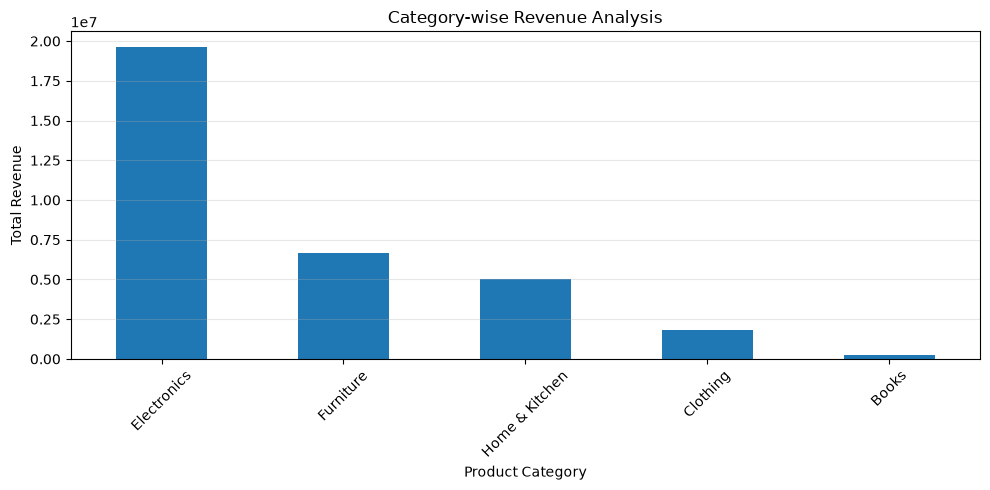

In [47]:
# Category-wise Revenue Analysis

category_revenue = (

df.groupby('category')['total_revenue']
.sum()
.sort_values(ascending=False)

)

print(category_revenue)

plt.figure(figsize=(10, 5))

category_revenue.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Category-wise Revenue Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

product_name
Laptop              8455664.50
Smartphone          7500604.95
Sofa                2983632.90
Monitor             2319060.50
Vacuum Cleaner      1858734.80
Desk                1520587.05
Microwave           1451589.50
Office Chair        1065189.75
Headphones           973694.15
Air Fryer            914760.30
Sneakers             593447.05
Bookshelf            593086.45
Cookware Set         538664.10
Jacket               533159.20
Coffee Table         501461.75
Keyboard             382276.20
Dress                286221.00
Jeans                267749.25
Blender              261858.40
T-Shirt              133972.95
Programming Book      86266.80
Biography             54776.65
Cookbook              52017.40
Fiction Novel         34903.25
Comics                30875.75
Name: total_revenue, dtype: float64
product_name
Laptop            8455664.50
Smartphone        7500604.95
Sofa              2983632.90
Monitor           2319060.50
Vacuum Cleaner    1858734.80
Desk              

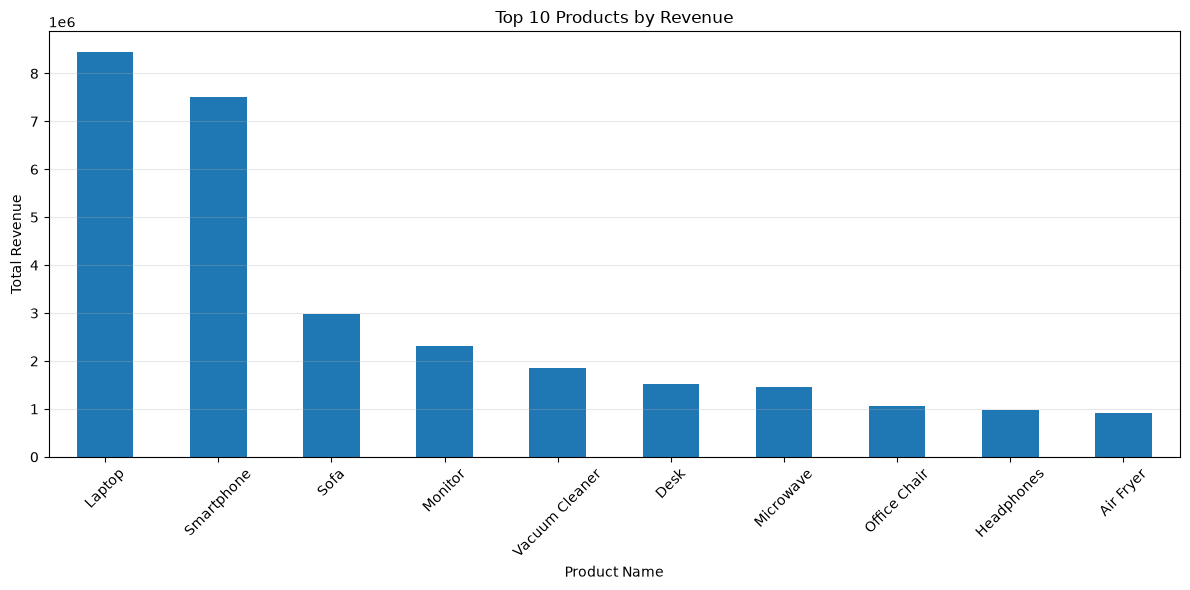

In [48]:
# Product-wise Revenue Analysis

product_revenue = (

    df.groupby('product_name')['total_revenue']
    .sum()
    .sort_values(ascending=False)

)

print(product_revenue)

top_10_products = product_revenue.head(10)

print(top_10_products)

plt.figure(figsize=(12, 6))

top_10_products.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product Name')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

region
West       7447168.70
South      7046683.90
Central    6732134.50
North      6135251.75
East       5782739.40
Name: total_revenue, dtype: float64


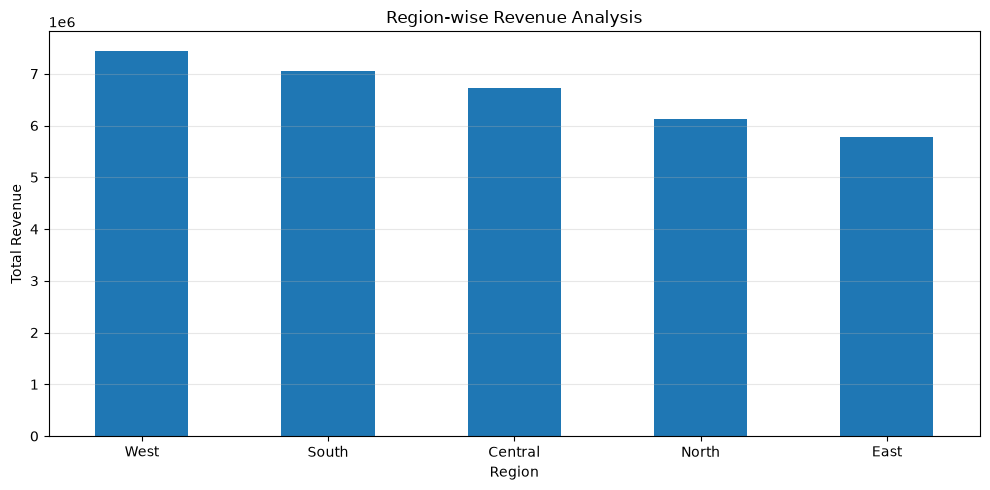

In [49]:
# Region-wise Revenue Analysis

region_revenue = (

    df.groupby('region')['total_revenue']
    .sum()
    .sort_values(ascending=False)

)

print(region_revenue) 

plt.figure(figsize=(10, 5))

region_revenue.plot(kind='bar')

plt.title('Region-wise Revenue Analysis')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

payment_method
Cash on Delivery    222
Credit Card         199
UPI                 196
Net Banking         193
Debit Card          191
Name: count, dtype: int64
payment_method
UPI                 7089943.25
Credit Card         6785797.55
Cash on Delivery    6614793.20
Net Banking         6449230.80
Debit Card          6262659.30
Name: total_revenue, dtype: float64


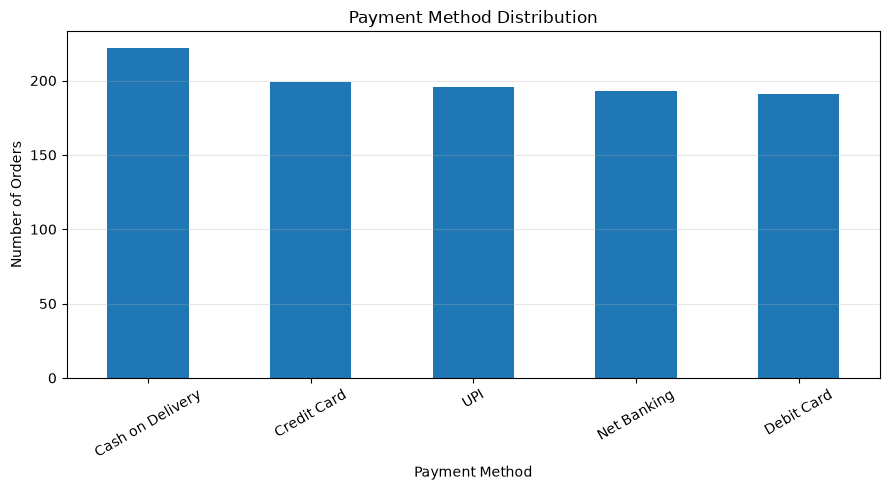

In [50]:
# Payment Method Analysis

payment_counts = (
    df['payment_method']
    .value_counts()
)

print(payment_counts)

payment_revenue = (
    df.groupby('payment_method')['total_revenue']
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue)

plt.figure(figsize=(9, 5))

payment_counts.plot(kind='bar')

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

payment_method
Cash on Delivery    222
Credit Card         199
UPI                 196
Net Banking         193
Debit Card          191
Name: count, dtype: int64
payment_method
UPI                 7089943.25
Credit Card         6785797.55
Cash on Delivery    6614793.20
Net Banking         6449230.80
Debit Card          6262659.30
Name: total_revenue, dtype: float64


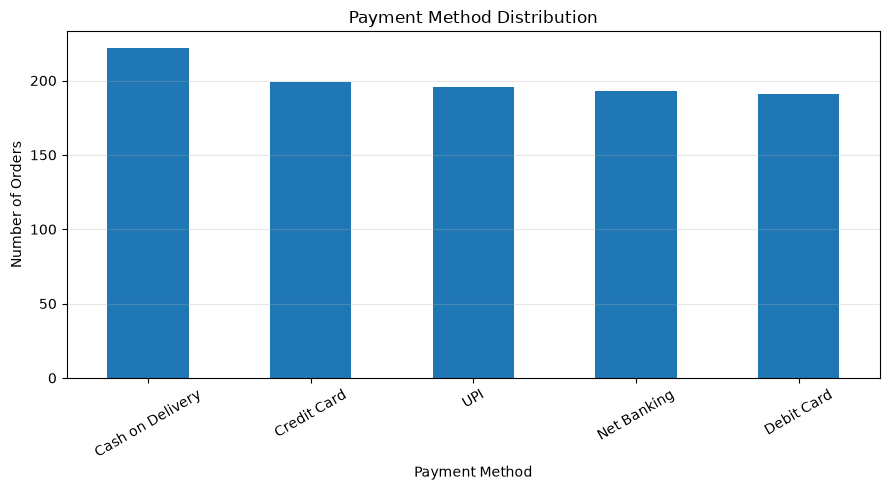

In [51]:
# Payment Method Analysis 

payment_counts = (
    df['payment_method']
    .value_counts()
)

print(payment_counts)

payment_revenue = (
    df.groupby('payment_method')['total_revenue']
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue) 

plt.figure(figsize=(9, 5))

payment_counts.plot(kind='bar')

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

customer_id
CUST1157    741024.60
CUST1006    684552.60
CUST1045    649846.70
CUST1148    620031.85
CUST1158    584340.15
              ...    
CUST1128      2534.00
CUST1033      2069.75
CUST1250      1302.45
CUST1065       829.80
CUST1179       387.60
Name: total_revenue, Length: 247, dtype: float64
customer_id
CUST1157    741024.60
CUST1006    684552.60
CUST1045    649846.70
CUST1148    620031.85
CUST1158    584340.15
CUST1233    570191.45
CUST1104    555746.50
CUST1059    520211.60
CUST1205    478226.10
CUST1154    472722.00
Name: total_revenue, dtype: float64


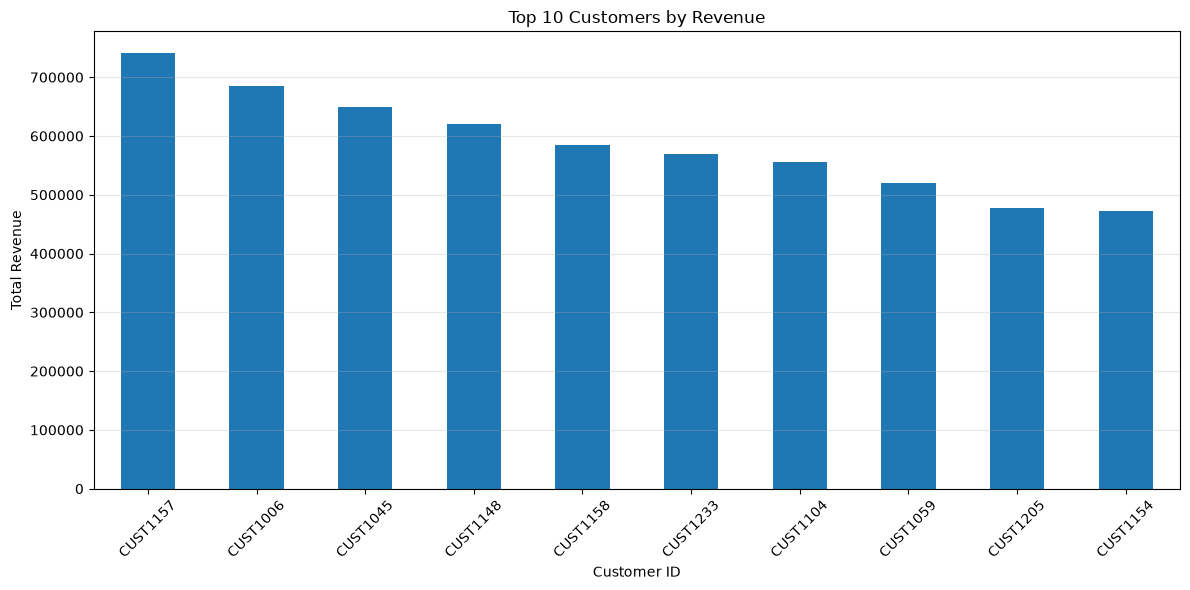

Average Customer Revenue: 134813.05587044536


In [52]:
# Customer -wise Revenue Analysis 

customer_revenue = (

    df.groupby('customer_id')['total_revenue']
    .sum()
    .sort_values(ascending=False)

)

print(customer_revenue) 

top_10_customers = customer_revenue.head(10)

print(top_10_customers)

plt.figure(figsize=(12, 6))

top_10_customers.plot(kind='bar')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Customer ID')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

average_customer_revenue = customer_revenue.mean()

print("Average Customer Revenue:", average_customer_revenue)

discount
0.00    211
0.05    203
0.10    201
0.15    210
0.20    174
Name: count, dtype: int64
discount
0.00    8644299.00
0.05    7139461.85
0.10    6206147.10
0.15    6596939.25
0.20    4291638.40
Name: total_revenue, dtype: float64
discount
0.00    40968.241706
0.05    35169.762808
0.10    30876.353731
0.15    31413.996429
0.20    24664.588506
Name: total_revenue, dtype: float64


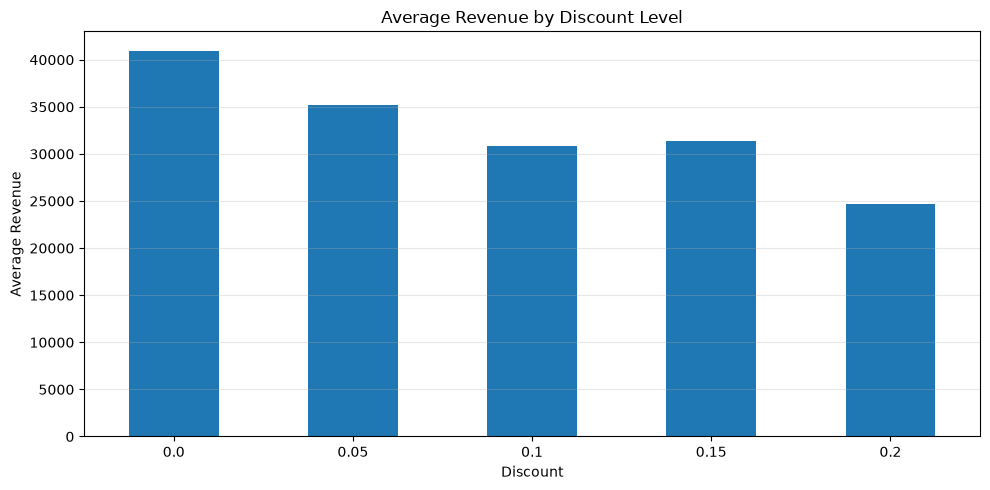

In [53]:
# Discount Impact Analysis

discount_counts = df['discount'].value_counts().sort_index()

print(discount_counts) 

discount_revenue = (

    df.groupby('discount')['total_revenue']
    .sum()
    .sort_index()

)

print(discount_revenue) 

discount_avg_revenue = (

    df.groupby('discount')['total_revenue']
    .mean()
    .sort_index()

)

print(discount_avg_revenue) 

plt.figure(figsize=(10, 5))

discount_avg_revenue.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Average Revenue by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
# EDA Summary and Business Insights 

# Generate key business metrics

# Overall business metrics

total_orders = df['order_id'].nunique()

total_revenue = df['total_revenue'].sum()

total_customers = df['customer_id'].nunique()

average_order_value = total_revenue / total_orders

delivered_orders = (df['status'] == 'Delivered').sum()

delivery_percentage = (delivered_orders / len(df)) * 100

print("Total Orders:", total_orders)
print("Total Revenue:", total_revenue)
print("Total Customers:", total_customers)
print("Average Order Value:", average_order_value)
print("Delivered Orders:", delivered_orders)
print("Delivery Percentage:", round(delivery_percentage, 2), "%")

Total Orders: 1000
Total Revenue: 33394254.599999998
Total Customers: 247
Average Order Value: 33394.2546
Delivered Orders: 777
Delivery Percentage: 77.31 %


In [55]:
# Identify business performance 

# Highest revenue category
print("Top Category:", category_revenue.idxmax())

# Highest revenue product
print("Top Product:", product_revenue.idxmax())

# Highest revenue region
print("Top Region:", region_revenue.idxmax())

# Most popular payment method
print("Popular Payment Method:", payment_counts.idxmax())

# Highest revenue customer
print("Top Customer:", customer_revenue.idxmax())

# Highest revenue month
print("Best Revenue Month:", monthly_revenue.idxmax())

Top Category: Electronics
Top Product: Laptop
Top Region: West
Popular Payment Method: Cash on Delivery
Top Customer: CUST1157
Best Revenue Month: 8


In [56]:
# Write your EDA conclusion 


## EDA Conclusion

# Exploratory Data Analysis was performed on the e-commerce sales 
# dataset to understand sales performance, customer behaviour, product performance, and business trends.

# The analysis covered:

# 1. Monthly revenue and order trends.
# 2. Month-over-Month revenue growth.
# 3. Category-wise and product-wise revenue.
# 4. Region-wise revenue performance.
# 5. Payment method preferences.
# 6. Order status distribution.
# 7. Customer-wise revenue analysis.
# 8. Discount impact analysis.

# The analysis helped identify important business patterns, 
# high-performing categories, revenue-generating products, customer contributions, and operational trends.

# These findings will support better business decision-making 
# and provide a foundation for further data preprocessing and AI-powered analytics.

In [57]:
# Final EDA validation

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTotal Orders:", df['order_id'].nunique())

print("Total Revenue:", df['total_revenue'].sum())

print("Total Customers:", df['customer_id'].nunique())

print("\nOrder Status:")
print(df['status'].value_counts())

print("\nCategory Distribution:")
print(df['category'].value_counts())

Dataset Shape: (1005, 13)

Missing Values:
order_id          0
order_date        0
customer_id       8
product_name      0
category          0
quantity          0
price             0
discount          6
region            5
payment_method    4
status            0
total_revenue     0
month             0
dtype: int64

Duplicate Rows: 5

Total Orders: 1000
Total Revenue: 33394254.599999998
Total Customers: 247

Order Status:
status
Delivered    777
Pending      116
Cancelled     79
Returned      33
Name: count, dtype: int64

Category Distribution:
category
Electronics       261
Clothing          221
Home & Kitchen    192
Furniture         174
Books             157
Name: count, dtype: int64
